# Rescue drone mission II: backward smoothing for refining trajectory estimates near a rocky shoreline.

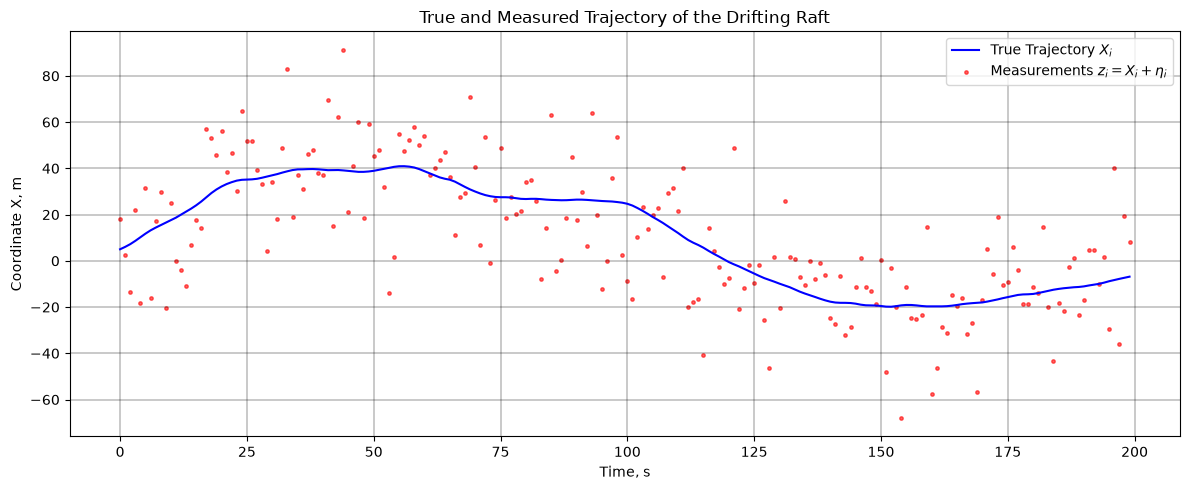

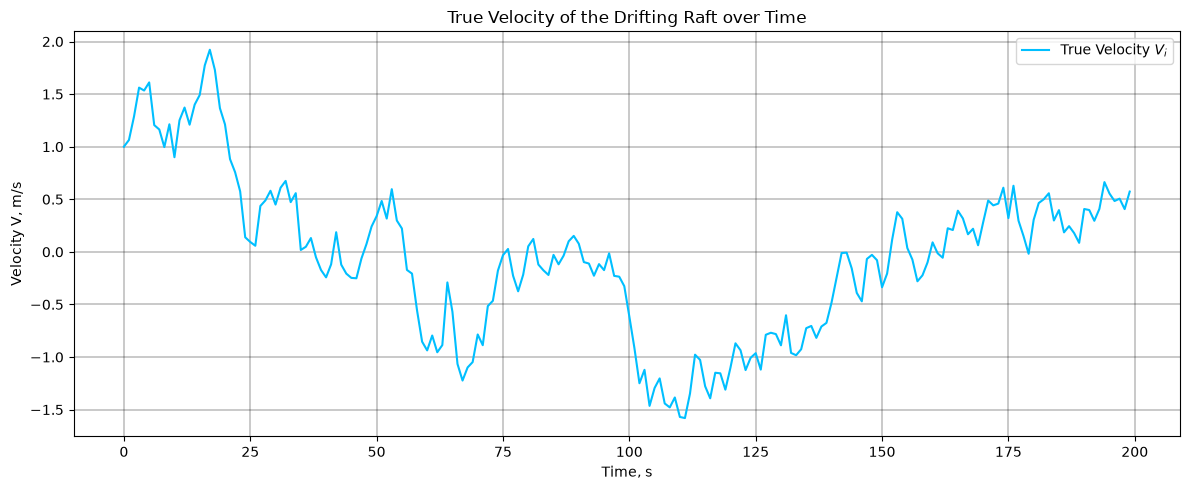

In [2]:
import numpy as np
from matplotlib import pyplot as plt

# define the constants to model the trajectory of the drifting raft
POINTS = 200
INIT_COORD = 5
INIT_VELOCITY = 1
T = 1

VARIANCE_A = 0.2**2
SIGMA_A = np.sqrt(VARIANCE_A)

VARIANCE_ETA = 20**2
SIGMA_ETA = np.sqrt(VARIANCE_ETA)

# a function to generate the true trajectory
def generate_true_trajectory(size, init_coord, init_velocity, sigma_a, t):
    traj_points = np.zeros(size)
    velocity_points = np.zeros(size)
    traj_points[0] = init_coord
    velocity_points[0] = init_velocity

    for i in range(1, size):
        acceleration = np.random.normal(loc=0.0, scale=sigma_a)
        traj_points[i] = traj_points[i-1] + velocity_points[i-1] * t + acceleration * t**2 / 2
        velocity_points[i] = velocity_points[i-1] + acceleration * t

    return traj_points, velocity_points

# a function to generate measured trajectory points based on the true trajectory
def generate_measured_trajectory(true_trajectory, sigma_eta):
    measured_trajectory = true_trajectory.copy()
    return measured_trajectory + np.random.normal(0.0, sigma_eta, size=measured_trajectory.size)

# generate the trajectories 
# true_trajectory_raft, true_velocity_raft = generate_true_trajectory(POINTS, INIT_COORD, INIT_VELOCITY, SIGMA_A, T)
# measured_trajectory_raft = generate_measured_trajectory(true_trajectory_raft, SIGMA_ETA)

# np.savetxt("true_trajectory_raft.txt", true_trajectory_raft)
# np.savetxt("true_velocity_raft.txt", true_velocity_raft)
# np.savetxt("measured_trajectory_raft.txt", measured_trajectory_raft)

# load the trajectories shared within the team
true_trajectory_raft = np.loadtxt("true_trajectory_raft.txt")
true_velocity_raft = np.loadtxt("true_velocity_raft.txt")
measured_trajectory_raft = np.loadtxt("measured_trajectory_raft.txt")

# plot the true trajectory and the measured points
steps = np.arange(true_trajectory_raft.size * T, step = T)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(steps, true_trajectory_raft, color="blue", linewidth=1.5, label="True Trajectory $X_i$")
ax.scatter(steps, measured_trajectory_raft, color="red", s=6, alpha=0.6, label="Measurements $z_i = X_i + \\eta_i$")
ax.set_title("True and Measured Trajectory of the Drifting Raft")
ax.set_xlabel("Time, s")
ax.set_ylabel("Coordinate X, m")
ax.grid(True, color="black", linewidth=0.3)
ax.legend(frameon=True)
fig.tight_layout()
plt.show()

# plot the velocity over time
steps = np.arange(true_velocity_raft.size * T, step = T)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(steps, true_velocity_raft, color="deepskyblue", linewidth=1.5, label="True Velocity $V_i$")
ax.set_title("True Velocity of the Drifting Raft over Time")
ax.set_xlabel("Time, s")
ax.set_ylabel("Velocity V, m/s")
ax.grid(True, color="black", linewidth=0.3)
ax.legend(frameon=True)
fig.tight_layout()
plt.show()

In [3]:
# state-space model of the drifting raft's motion

# transition matrix Phi
PHI = np.array([[1, T],
                [0, 1]])

# input matrix G that defines how the random acceleration a_i influences the state vector
G = np.array([[T**2 / 2],
              [T]])

# observation matrix H that relates the measurement vector to the state vector 
H = np.array([[1, 0]])

# covariance matrix Q of the state noise G * a_i
Q = G @ G.T * VARIANCE_A

# covariance matrix R of the measurement noise
R = np.array([[VARIANCE_ETA]])

In [4]:
# setting the initial conditions for the filtered estimate and the filtration error covariance matrix

# initial filtered estimate of the state vector 
X_0_0 = np.array([[INIT_COORD],
                  [INIT_VELOCITY]])

# initial filtration error covariance matrix, identical to the matrix initially used in Assignment 6
P_0_0 = np.array([[10000, 0],
                  [0, 10000]])

In [5]:
# Kalman filter as a function
def kalman_filter(measurements, phi, h, q, r, x_0_0, p_0_0):
    size = measurements.size

    x_pred = np.zeros((size, 2, 1))   # predicted state X_{i,i-1}
    p_pred = np.zeros((size, 2, 2))   # prediction error covariance P_{i,i-1}
    x_filt = np.zeros((size, 2, 1))   # filtered state X_{i,i}
    p_filt = np.zeros((size, 2, 2))   # filtration error covariance P_{i,i}
    k = np.zeros((size, 2, 1))        # filter gain K_i

    identity = np.eye(2)
    x_prev = x_0_0
    p_prev = p_0_0
    x_filt[0] = x_0_0
    p_filt[0] = p_0_0

    for i in range(1, size):
        # prediction
        x_pred[i] = phi @ x_prev
        p_pred[i] = phi @ p_prev @ phi.T + q

        # filtration
        k[i] = p_pred[i] @ h.T @ np.linalg.inv(h @ p_pred[i] @ h.T + r)
        x_filt[i] = x_pred[i] + k[i] * (measurements[i] - h @ x_pred[i])
        p_filt[i] = (identity - k[i] @ h) @ p_pred[i]

        x_prev = x_filt[i]
        p_prev = p_filt[i]

    return x_pred, p_pred, x_filt, p_filt, k

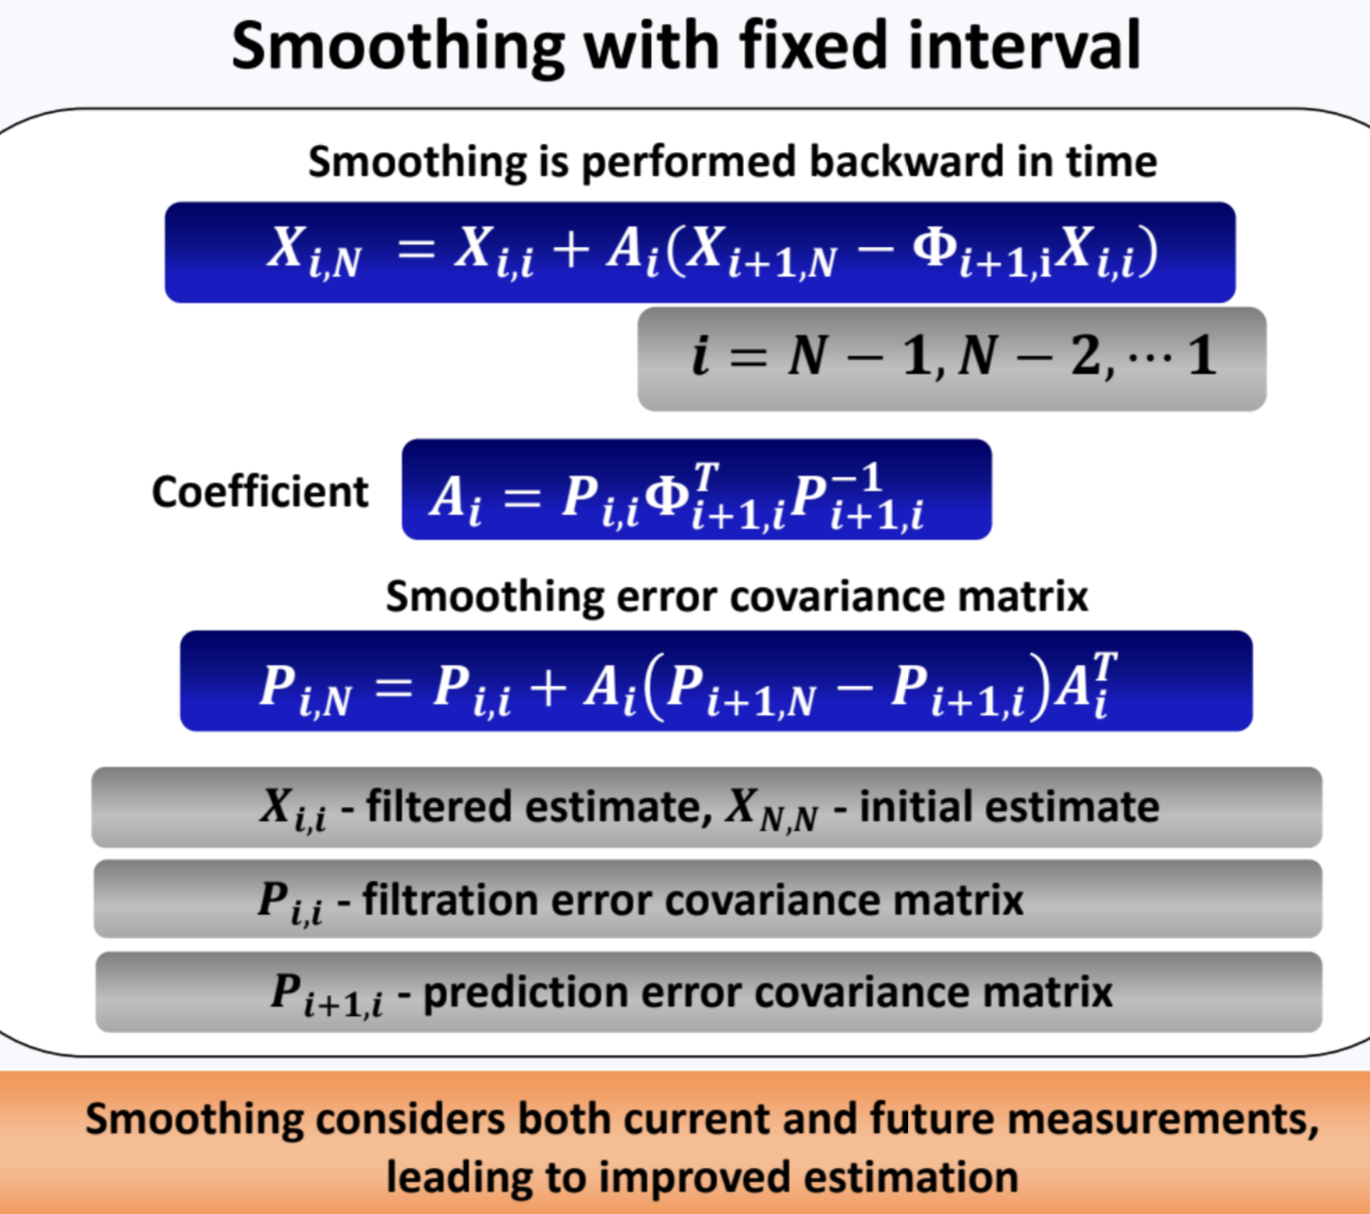

In [6]:
# perform backward smoothing of the filtered estimates
def run_backward_smoothing(x_filt, p_filt, p_pred, phi):
    n = x_filt.shape[0] - 1
    x_smooth = np.zeros_like(x_filt)
    p_smooth = np.zeros_like(p_filt)
    a = np.zeros((n, 2, 2))

    x_smooth[n] = x_filt[n]
    p_smooth[n] = p_filt[n]

    for i in range(n - 1, -1, -1):
        a[i] = p_filt[i] @ phi.T @ np.linalg.inv(p_pred[i + 1])
        x_smooth[i] = x_filt[i] + a[i] @ (x_smooth[i + 1] - phi @ x_filt[i])
        p_smooth[i] = p_filt[i] + a[i] @ (p_smooth[i + 1] - p_pred[i + 1]) @ a[i].T
    
    return x_smooth, p_smooth

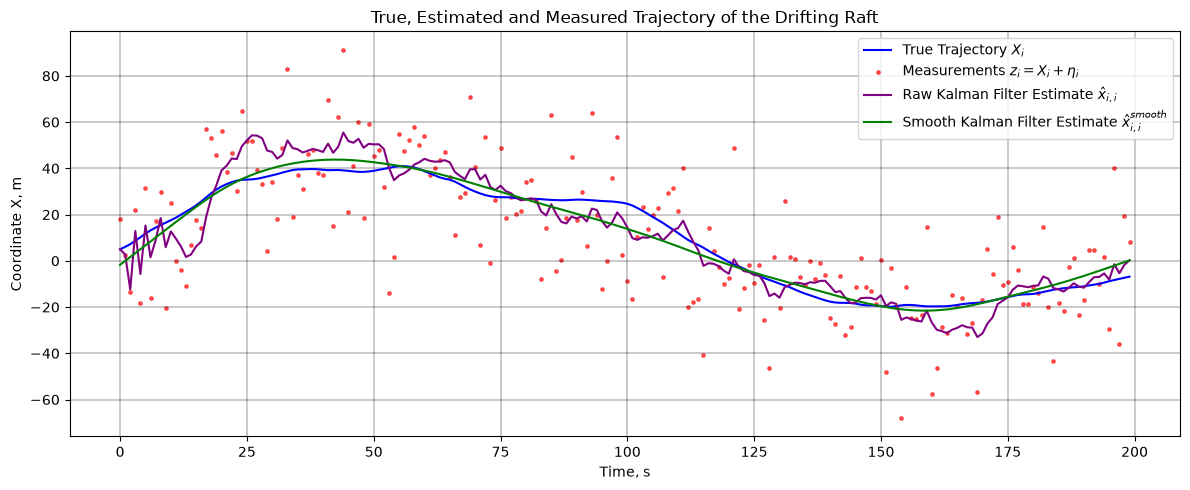

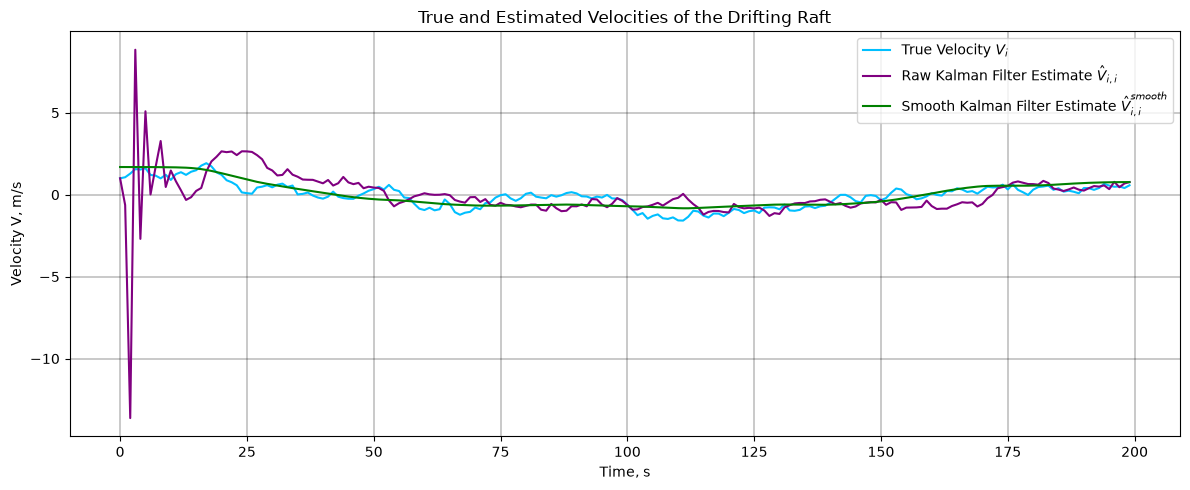

In [7]:
# apply Kalman filtering
x_pred, p_pred, x_filt, p_filt, _ = kalman_filter(measured_trajectory_raft, PHI, H, Q, R, X_0_0, P_0_0)

# apply backward smoothing of the filtered estimates
x_smooth, _ = run_backward_smoothing(x_filt, p_filt, p_pred, PHI)

# plot the raw filtered estimates and the smoothed estimates, alongside the true and measured trajectories
steps = np.arange(true_trajectory_raft.size * T, step = T)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(steps, true_trajectory_raft, color="blue", linewidth=1.5, label="True Trajectory $X_i$")
ax.scatter(steps, measured_trajectory_raft, color="red", s=6, alpha=0.6, label="Measurements $z_i = X_i + \\eta_i$")
ax.plot(steps, x_filt[:, 0, 0], color="purple", linewidth=1.5, label="Raw Kalman Filter Estimate $\\hat{x}_{i,i}$")
ax.plot(steps, x_smooth[:, 0, 0], color="green", linewidth=1.5, label="Smooth Kalman Filter Estimate $\\hat{x}^{smooth}_{i,i}$")
ax.set_title("True, Estimated and Measured Trajectory of the Drifting Raft")
ax.set_xlabel("Time, s")
ax.set_ylabel("Coordinate X, m")
ax.grid(True, color="black", linewidth=0.3)
ax.legend(frameon=True)
fig.tight_layout()
plt.show()

# plot the raw filtered estimates and the smoothed estimates, alongside the true velocities
steps = np.arange(true_trajectory_raft.size * T, step = T)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(steps, true_velocity_raft, color="deepskyblue", linewidth=1.5, label="True Velocity $V_i$")
ax.plot(steps, x_filt[:, 1, 0], color="purple", linewidth=1.5, label="Raw Kalman Filter Estimate $\\hat{V}_{i,i}$")
ax.plot(steps, x_smooth[:, 1, 0], color="green", linewidth=1.5, label="Smooth Kalman Filter Estimate $\\hat{V}^{smooth}_{i,i}$")
ax.set_title("True and Estimated Velocities of the Drifting Raft")
ax.set_xlabel("Time, s")
ax.set_ylabel("Velocity V, m/s")
ax.grid(True, color="black", linewidth=0.3)
ax.legend(frameon=True)
fig.tight_layout()
plt.show()

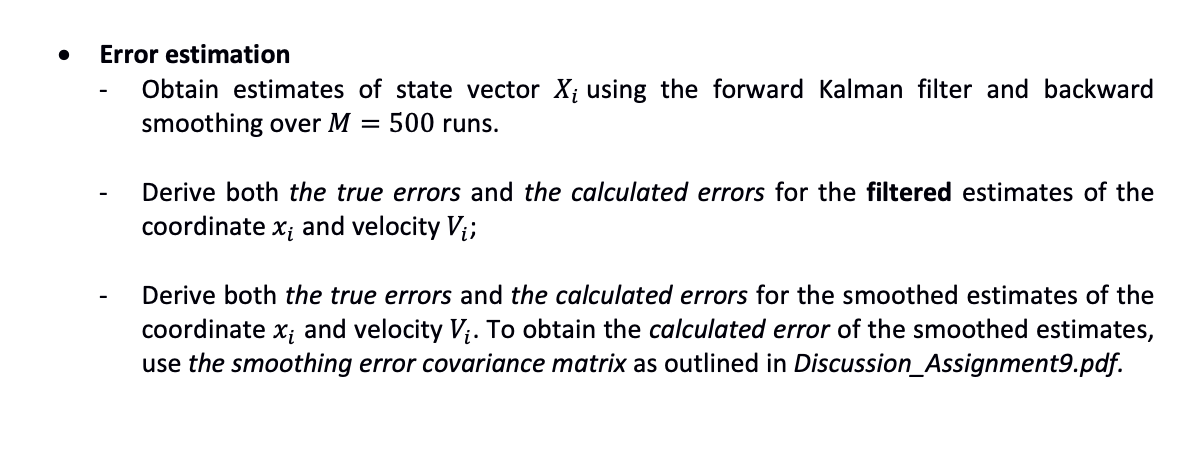

In [9]:
# error estimation

M = 500

position_errors = np.zeros((M, POINTS))

for m in range(M):
    true_trajectory, true_velocity = generate_true_trajectory(POINTS, INIT_COORD, INIT_VELOCITY, SIGMA_A, T)
    measurements = generate_measured_trajectory(true_trajectory, SIGMA_ETA)

    _, p_pred, x_filt, p_filt, _ = kalman_filter(
        measurements, PHI, H, Q, R, X_0_0, P_0_0
    )
    x_smooth, _ = run_backward_smoothing(x_filt, p_filt, p_pred, PHI)

    position_errors[m] = (
        x_filt[:, 0, 0] - true_trajectory
    )

    true_rmse = np.sqrt(np.mean(position_errors**2, axis=0))
    calculated_sigma = np.sqrt(p_filt[:, 0, 0])